        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
Binary labels (first 10): [0 0 0 1 0 0 0 0 0 1]

Decision Tree Classifier - START
Confusion Matrix:
 [[51 13]
 [23 24]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.80      0.74        64
           1       0.65      0.51      0.57        47

    accuracy                         

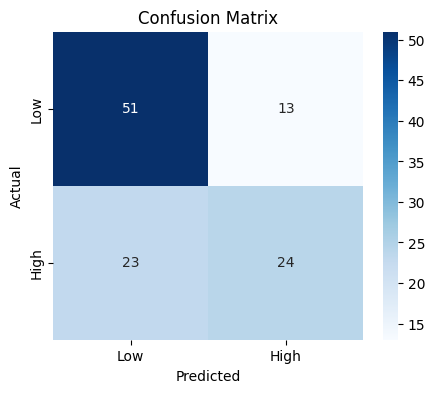


Decision Tree Classifier - ENDS

Random Forest Classifier - START


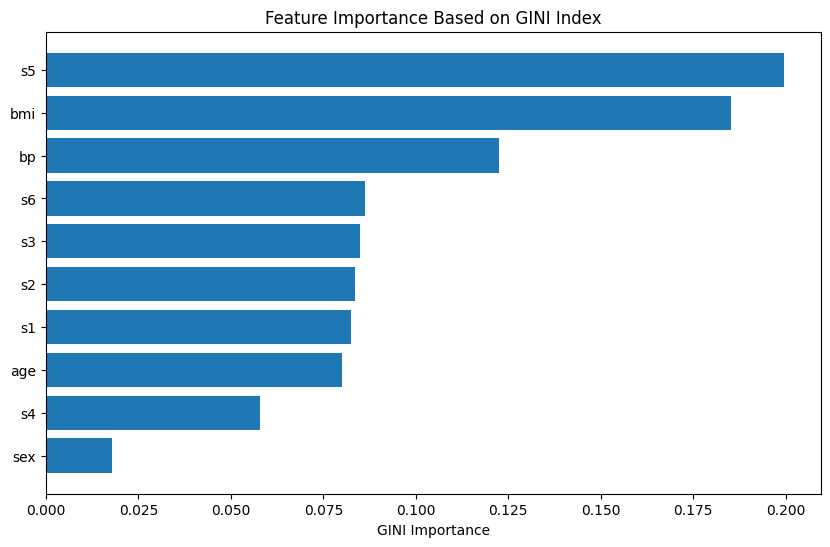

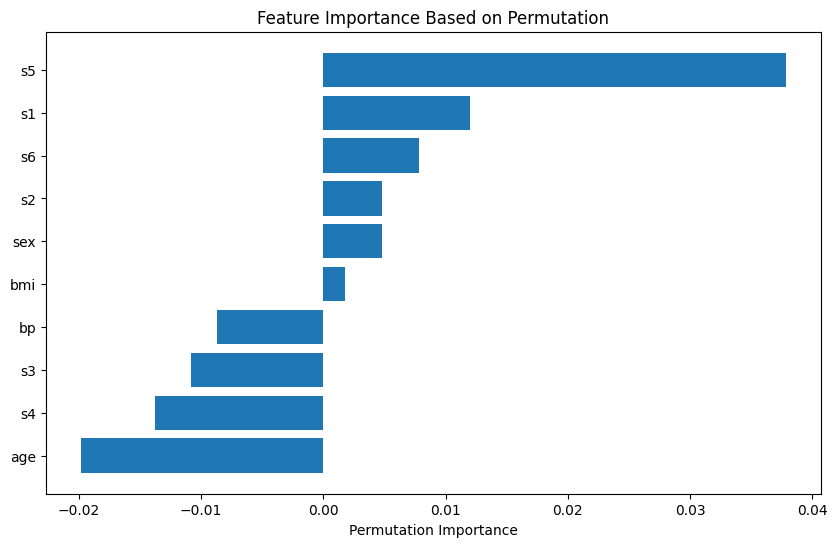


Random Forest Classifier - ENDS
Decision Tree Accuracy: 0.68
Random Forest Accuracy: 0.72


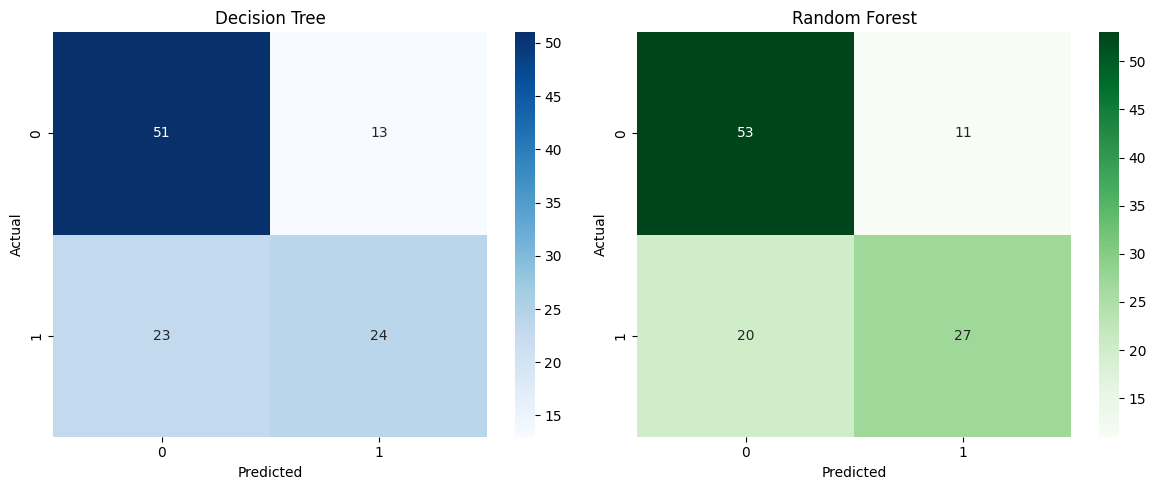

In [15]:
##Classifications

##Task 1 & Task 2: Load and Prepare the Data

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import Binarizer

import pandas as pd
import numpy as np

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier

from sklearn.inspection import permutation_importance

# Load the dataset
data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Convert target to binary (classification): 0 = Low, 1 = High
y_binary = np.where(y > y.mean(), 1, 0)  # mean thresholding

# Optional: show summary
print(X.head())
print("Binary labels (first 10):", y_binary[:10])

##Task 3: Split into Train/Test (75%-25%)

X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.25, random_state=1)

##Task 4: Decision Tree Classifier

print("\nDecision Tree Classifier - START")

DTC = DecisionTreeClassifier(random_state=1)
DTC.fit(X_train, y_train)

##Task 5: Evaluate Decision Tree Model

# Predict on test set
y_pred_DT = DTC.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_DT)
print("Confusion Matrix:\n", cm)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_DT))

# Accuracy score
accuracy = accuracy_score(y_test, y_pred_DT)
print("\nAccuracy Score:", accuracy)

# Optional: Plot confusion matrix
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print("\nDecision Tree Classifier - ENDS")

##Task 6:  Random Forest Classifier

print("\nRandom Forest Classifier - START")

# Create and train the Random Forest model with 150 trees
RF = RandomForestClassifier(n_estimators=150, random_state=1)
RF.fit(X_train, y_train)

# Predict on the test data
y_pred_RF = RF.predict(X_test)

##Task 7: Find and plot the feature importance based on GINI index

# Get feature importances from the trained Random Forest model
importances = RF.feature_importances_

# Create a DataFrame to display nicely
feature_names = data.feature_names  # from the dataset
importance_df = pd.DataFrame({'Feature': feature_names,'Importance (GINI)': importances}).sort_values(by='Importance (GINI)', ascending=False)

# Plot the feature importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance (GINI)'])
plt.xlabel('GINI Importance')
plt.title('Feature Importance Based on GINI Index')
plt.gca().invert_yaxis()
plt.show()

##Task 8: Find and plot the permutation importance.

# Compute permutation importance on the test set
perm_importance = permutation_importance(RF, X_test, y_test, n_repeats=30, random_state=42)

# Convert to DataFrame for easy plotting
perm_df = pd.DataFrame({'Feature': data.feature_names,'Importance (Permutation)': perm_importance.importances_mean}).sort_values(by='Importance (Permutation)', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(perm_df['Feature'], perm_df['Importance (Permutation)'])
plt.xlabel('Permutation Importance')
plt.title('Feature Importance Based on Permutation')
plt.gca().invert_yaxis()
plt.show()

print("\nRandom Forest Classifier - ENDS")


###Bonus Section: Model Improvements and Comparative Analysis

#Compare Models (Decision Tree vs Random Forest):

# Accuracy comparison
DT_acc = accuracy_score(y_test, y_pred_DT)  # From Task 5
RF_acc = accuracy_score(y_test, y_pred_RF)  # From Task 6

print(f"Decision Tree Accuracy: {DT_acc:.2f}")
print(f"Random Forest Accuracy: {RF_acc:.2f}")

# Confusion matrices
cm_dt = confusion_matrix(y_test, y_pred_DT)
cm_rf = confusion_matrix(y_test, y_pred_RF)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree Confusion Matrix
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Decision Tree')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Random Forest Confusion Matrix
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

